# TBATS for Time Series Forecasting

**Objective:** Forecast hourly retail demand containing two seasonal cycles: daily (24 observations) and weekly (168 observations).

TBATS stands for Trigonometric seasonality, Box-Cox transformation, ARMA errors, Trend, and Seasonal components. It is designed for complex seasonal patterns, including multiple and non-integer seasonal periods.

This notebook covers synthetic data generation, exploratory analysis, chronological splitting, TBATS fitting, validation, evaluation, residual diagnostics, and future forecasting.

## 1. Install and import libraries

Install dependencies if needed. Package compatibility can vary across Python and NumPy versions.

In [3]:
# Run once if required:
# %pip install tbats numpy pandas matplotlib scikit-learn statsmodels

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tbats import TBATS
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
np.random.seed(42)

## 2. Generate synthetic hourly demand

We simulate 12 weeks of store demand with a gradual trend, a daily pattern, a weekday/weekend effect, and noise. This is an educational dataset, not real retail data.

In [4]:
n = 12 * 7 * 24
index = pd.date_range("2024-01-01", periods=n, freq="h")
t = np.arange(n)
hour = index.hour.to_numpy()
dow = index.dayofweek.to_numpy()

trend = 0.0025 * t
daily = 12 + 7*np.sin(2*np.pi*(hour-7)/24) + 2.5*np.cos(4*np.pi*hour/24)
weekly = np.select([dow == 5, dow == 6], [5.0, -4.0], default=0.0)
noise = np.random.normal(0, 2.5, n)
demand = np.maximum(35 + trend + daily + weekly + noise, 0)

df = pd.DataFrame({"demand": demand}, index=index)
df.index.name = "timestamp"
display(df.head())
print("Observations:", len(df), "| Frequency:", pd.infer_freq(df.index))

,demand
timestamp,
2024-01-01 00:00:00,43.980305
2024-01-01 01:00:00,41.821903
2024-01-01 02:00:00,43.112741
2024-01-01 03:00:00,44.752897
2024-01-01 04:00:00,40.224869


Observations: 2016 | Frequency: h


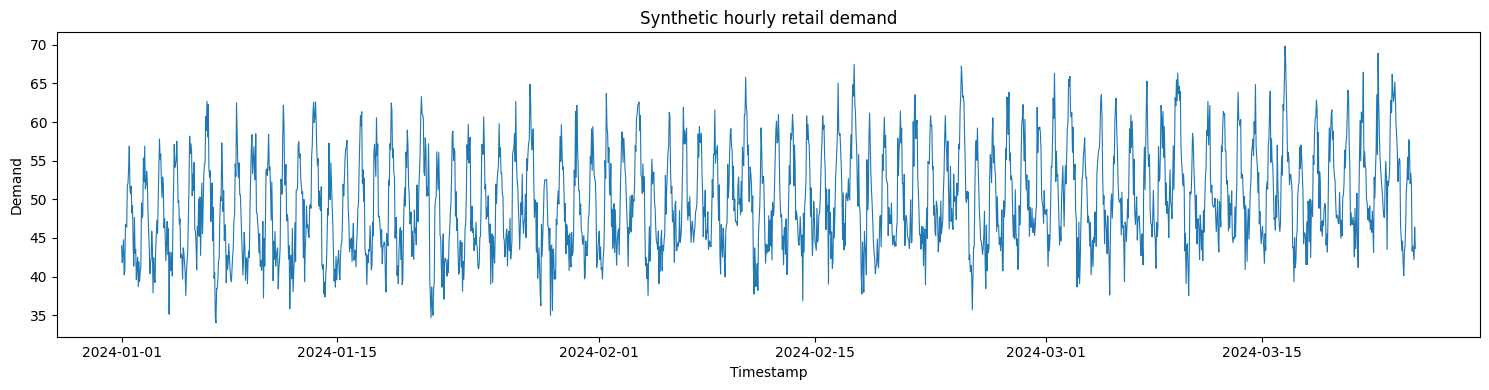

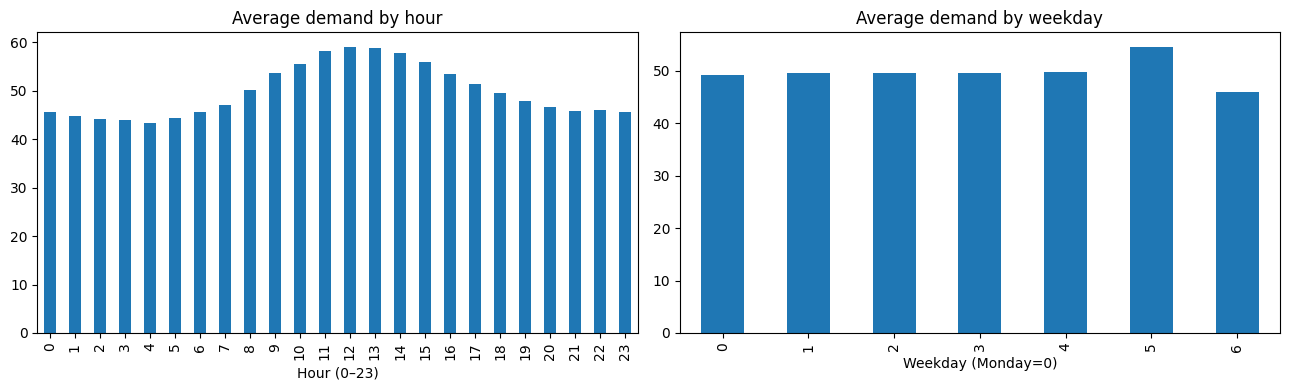

In [5]:
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(df.index, df.demand, linewidth=0.8)
ax.set(title="Synthetic hourly retail demand", xlabel="Timestamp", ylabel="Demand")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df.groupby(df.index.hour).demand.mean().plot(kind="bar", ax=axes[0], title="Average demand by hour")
df.groupby(df.index.dayofweek).demand.mean().plot(kind="bar", ax=axes[1], title="Average demand by weekday")
axes[0].set_xlabel("Hour (0–23)")
axes[1].set_xlabel("Weekday (Monday=0)")
plt.tight_layout()
plt.show()

## 3. TBATS components and intuition

| Letter | Component | Role |
|---|---|---|
| T | Trigonometric seasonality | Represents seasonal cycles using sine/cosine terms |
| B | Box-Cox transformation | Can stabilize changing variance |
| A | ARMA errors | Captures autocorrelation left in errors |
| T | Trend | Models trend; can be damped |
| S | Seasonal components | Supports multiple seasonal periods |

For seasonal period `m`, a Fourier-style seasonal representation can be written conceptually as:

$$
s_t = \sum_{k=1}^{K}\left[a_k\cos(2\pi kt/m)+b_k\sin(2\pi kt/m)\right]
$$

Here `K` controls the number of harmonics. TBATS estimates seasonal states and parameters in a state-space framework; this equation illustrates the trigonometric representation rather than the complete TBATS specification.

A simplified conceptual decomposition is:

$$
y_t = \ell_t + d_t + \sum_i s_{i,t} + \varepsilon_t
$$

where level/trend, seasonal components, and errors combine to describe the observed series.

## 4. Chronological train / validation / test split

We use 10 weeks for training, one week for validation, and one week for final testing. Never shuffle time-series observations randomly.

In [6]:
train_n = 10 * 7 * 24
val_n = 7 * 24
train = df.demand.iloc[:train_n]
validation = df.demand.iloc[train_n:train_n + val_n]
test = df.demand.iloc[train_n + val_n:]

print("Train:", len(train), train.index.min(), "to", train.index.max())
print("Validation:", len(validation), validation.index.min(), "to", validation.index.max())
print("Test:", len(test), test.index.min(), "to", test.index.max())

Train: 1680 2024-01-01 00:00:00 to 2024-03-10 23:00:00
Validation: 168 2024-03-11 00:00:00 to 2024-03-17 23:00:00
Test: 168 2024-03-18 00:00:00 to 2024-03-24 23:00:00


## 5. Establish a simple baseline

A baseline helps determine whether the more complex TBATS model adds value.

In [7]:
baseline = np.repeat(train.mean(), len(validation))
print("Mean baseline MAE:", mean_absolute_error(validation, baseline))
print("Mean baseline RMSE:", np.sqrt(mean_squared_error(validation, baseline)))

Mean baseline MAE: 5.184601865187531
Mean baseline RMSE: 6.556704831128662


## 6. Fit TBATS with daily and weekly seasonality

For hourly data:
- `24` = one day.
- `168` = seven days.

The fit below disables Box-Cox initially, includes a trend and damped trend, and enables ARMA errors. TBATS may take time to fit, particularly with long histories or many seasonal periods.

In [ ]:
estimator = TBATS(
    seasonal_periods=[24, 168],
    use_box_cox=False,
    use_trend=True,
    use_damped_trend=True,
    use_arma_errors=True,
    n_jobs=1
)
model = estimator.fit(train.to_numpy())
print(model)

## 7. Validation forecast and prediction interval

The TBATS Python package commonly returns `(forecast, confidence_intervals)` when `confidence_level` is provided. The following handles either a tuple or forecast-only return.

In [ ]:
result = model.forecast(steps=len(validation), confidence_level=0.95)
if isinstance(result, tuple):
    val_forecast, val_interval = result
else:
    val_forecast, val_interval = result, None
val_forecast = np.asarray(val_forecast).reshape(-1)

print("Forecast points:", len(val_forecast))

In [ ]:
plt.figure(figsize=(15, 5))
plt.plot(train.index[-168:], train.iloc[-168:], label="Recent training")
plt.plot(validation.index, validation, label="Actual validation", linewidth=2)
plt.plot(validation.index, val_forecast, label="TBATS forecast", linewidth=2)
if val_interval is not None:
    ci = np.asarray(val_interval)
    if ci.ndim == 2 and ci.shape[0] == len(val_forecast) and ci.shape[1] >= 2:
        plt.fill_between(validation.index, ci[:, 0], ci[:, 1], alpha=.2, label="95% prediction interval")
plt.title("TBATS validation forecast")
plt.xlabel("Timestamp"); plt.ylabel("Demand"); plt.legend()
plt.tight_layout(); plt.show()

## 8. Evaluation metrics

- **MAE:** average absolute error.
- **RMSE:** penalizes larger errors more heavily.
- **WMAPE:** total absolute error divided by total absolute actual demand.
- **Bias:** signed error; positive means over-forecasting under the convention below.

$$
WMAPE = \frac{\sum_t |y_t-\hat y_t|}{\sum_t |y_t|}\times100
$$

$$
Bias = \frac{\sum_t(\hat y_t-y_t)}{\sum_t|y_t|}\times100
$$

In [ ]:
def metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    denom = np.sum(np.abs(actual))
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "WMAPE (%)": np.sum(np.abs(actual-predicted))/denom*100 if denom else np.nan,
        "Bias (%)": np.sum(predicted-actual)/denom*100 if denom else np.nan
    }

validation_metrics = metrics(validation, val_forecast)
pd.Series(validation_metrics, name="Validation metrics")

## 9. Refit on training + validation, then test

After model configuration is selected, refit using all data available before the test window. Keep the test period untouched until this final evaluation.

In [ ]:
train_val = pd.concat([train, validation])
final_estimator = TBATS(
    seasonal_periods=[24, 168],
    use_box_cox=False,
    use_trend=True,
    use_damped_trend=True,
    use_arma_errors=True,
    n_jobs=1
)
final_model = final_estimator.fit(train_val.to_numpy())
test_result = final_model.forecast(steps=len(test), confidence_level=0.95)
if isinstance(test_result, tuple):
    test_forecast, test_interval = test_result
else:
    test_forecast, test_interval = test_result, None
test_forecast = np.asarray(test_forecast).reshape(-1)

test_metrics = metrics(test, test_forecast)
pd.DataFrame([validation_metrics, test_metrics], index=["Validation", "Test"])

In [ ]:
plt.figure(figsize=(15, 5))
plt.plot(test.index, test, label="Actual test", linewidth=2)
plt.plot(test.index, test_forecast, label="TBATS forecast", linewidth=2)
if test_interval is not None:
    ci = np.asarray(test_interval)
    if ci.ndim == 2 and ci.shape[0] == len(test_forecast) and ci.shape[1] >= 2:
        plt.fill_between(test.index, ci[:, 0], ci[:, 1], alpha=.2, label="95% prediction interval")
plt.title("TBATS test forecast")
plt.xlabel("Timestamp"); plt.ylabel("Demand"); plt.legend()
plt.tight_layout(); plt.show()

## 10. Residual diagnostics

Residuals are actual observations minus fitted values. Check for patterns and remaining autocorrelation. The `y_hat` fitted-values attribute is available in commonly used `tbats` package versions; inspect the fitted model if your version exposes it differently.

In [ ]:
fitted = np.asarray(final_model.y_hat).reshape(-1)
residuals = train_val.to_numpy() - fitted

plt.figure(figsize=(14, 4))
plt.plot(train_val.index, residuals)
plt.axhline(0, linestyle="--")
plt.title("In-sample residuals"); plt.xlabel("Timestamp"); plt.ylabel("Residual")
plt.tight_layout(); plt.show()

plot_acf(residuals, lags=72)
plt.title("Residual autocorrelation")
plt.tight_layout(); plt.show()

display(acorr_ljungbox(residuals, lags=[24, 48], return_df=True))

## 11. Forecast the next seven days

For a production-style demonstration, refit on all observations currently available and forecast the next 168 hours.

In [ ]:
production_estimator = TBATS(
    seasonal_periods=[24, 168],
    use_box_cox=False,
    use_trend=True,
    use_damped_trend=True,
    use_arma_errors=True,
    n_jobs=1
)
production_model = production_estimator.fit(df.demand.to_numpy())
future_result = production_model.forecast(steps=168, confidence_level=0.95)
if isinstance(future_result, tuple):
    future_forecast, future_interval = future_result
else:
    future_forecast, future_interval = future_result, None

future_index = pd.date_range(df.index[-1] + pd.Timedelta(hours=1), periods=168, freq="h")
future = pd.DataFrame({"forecast": np.asarray(future_forecast).reshape(-1)}, index=future_index)
display(future.head())

In [ ]:
plt.figure(figsize=(15, 5))
plt.plot(df.index[-168:], df.demand.iloc[-168:], label="Recent actual")
plt.plot(future.index, future.forecast, label="Next 7-day forecast")
if future_interval is not None:
    ci = np.asarray(future_interval)
    if ci.ndim == 2 and ci.shape[0] == 168 and ci.shape[1] >= 2:
        plt.fill_between(future.index, ci[:, 0], ci[:, 1], alpha=.2, label="95% prediction interval")
plt.title("Future hourly demand forecast")
plt.xlabel("Timestamp"); plt.ylabel("Demand"); plt.legend()
plt.tight_layout(); plt.show()

## 12. Important parameters

| Parameter | Meaning |
|---|---|
| `seasonal_periods` | Seasonal cycle lengths in number of observations |
| `use_box_cox` | Enable/disable Box-Cox transformation |
| `use_trend` | Include a trend component |
| `use_damped_trend` | Allow trend to dampen over the forecast horizon |
| `use_arma_errors` | Model autocorrelation in errors |
| `n_jobs` | Parallel jobs used during estimation |

Examples of seasonal periods:
- Hourly daily: `24`
- Hourly weekly: `168`
- Half-hourly daily: `48`
- Daily weekly: `7`
- Daily annual: approximately `365.25`
- Monthly annual: `12`

## 13. Advantages and limitations

**Advantages**
- Handles multiple seasonal periods.
- Trigonometric terms can represent complex seasonal shapes.
- Supports non-integer seasonal periods.
- Can include Box-Cox transformation, trend, damped trend, and ARMA errors.

**Limitations**
- Can be computationally expensive.
- Requires enough history to estimate long seasonal cycles.
- Does not natively incorporate arbitrary external regressors such as price, promotion, or weather in the same way as regression-based models.
- More complex does not necessarily mean more accurate.

## 14. Comparison with other models

| Model | Seasonal support | Multiple seasonalities |
|---|---|---|
| ARIMA | Not explicitly seasonal | No |
| SARIMA | Seasonal | Commonly one seasonal period |
| Auto-ARIMA | Depends on seasonal configuration | Implementation-dependent |
| Holt-Winters | One seasonal period | Not designed for multiple cycles |
| TBATS | Yes | Yes |
| Prophet | Yes | Multiple seasonalities can be specified |

## 15. Supply-chain and retail applications

- Hourly store and e-commerce order demand.
- Warehouse picking, receiving, and dispatch workload.
- Daily/weekly patterns in resource consumption.
- Operational volume forecasting for staffing and capacity planning.

For item-location forecasting, check whether the series has enough history and stable seasonal structure. Intermittent demand, stockouts, assortment changes, and promotions may require other methods or explanatory variables.

## 16. Practical checklist

1. Verify timestamp regularity and missing observations.
2. Identify seasonal periods in units of observations.
3. Ensure sufficient history for long cycles.
4. Use chronological train/validation/test splits.
5. Compare against simple baselines and alternative models.
6. Evaluate MAE, RMSE, WMAPE, and bias.
7. Inspect residuals and prediction intervals.
8. Refit only after model selection and monitor performance.

## Key takeaway

TBATS is a useful candidate when multiple seasonal patterns are important. Its added complexity should be justified by out-of-sample performance, residual checks, and business relevance.

## References

- De Livera, Hyndman & Snyder (2011), *Forecasting time series with complex seasonal patterns using exponential smoothing*, Journal of the American Statistical Association.
- Python TBATS package: https://github.com/intive-DataScience/tbats
- Forecasting: Principles and Practice – Complex seasonality: https://otexts.com/fpp3/complexseasonality.html